# **Part5: Regularization Techniques(L1 and L2)**

In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import Ridge, Lasso, LinearRegression, LogisticRegression
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_squared_error, accuracy_score
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv('/content/drive/MyDrive/A1_Classification/data/cleaned_data.csv')

X = df.drop(columns='median_house_value')  # Features
y = df['median_house_value']  # Target variable

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# Standardize the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## **1. For Linear Regression model**

In [ ]:
# Non-regularized linear regression for comparison
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
lr_pred = lr.predict(X_test_scaled)
lr_mse = mean_squared_error(y_test, lr_pred)

In [ ]:
# Ridge Regression (L2 Regularization)
ridge = Ridge()
ridge_params = {'alpha': np.logspace(-4, 4, 50)} # generates 50 values for alpha logarithmically spaced between 10^-4 ~ 10^4
ridge_grid = GridSearchCV(ridge, ridge_params, cv=5, scoring='neg_mean_squared_error')
ridge_grid.fit(X_train_scaled, y_train)

GridSearchCV(cv=5, estimator=Ridge(),
             param_grid={'alpha': array([1.00000000e-04, 1.45634848e-04, 2.12095089e-04, 3.08884360e-04,
       4.49843267e-04, 6.55128557e-04, 9.54095476e-04, 1.38949549e-03,
       2.02358965e-03, 2.94705170e-03, 4.29193426e-03, 6.25055193e-03,
       9.10298178e-03, 1.32571137e-02, 1.93069773e-02, 2.81176870e-02,
       4.09491506e-02, 5.96362332e-02, 8.68511374e-02, 1....
       3.72759372e+00, 5.42867544e+00, 7.90604321e+00, 1.15139540e+01,
       1.67683294e+01, 2.44205309e+01, 3.55648031e+01, 5.17947468e+01,
       7.54312006e+01, 1.09854114e+02, 1.59985872e+02, 2.32995181e+02,
       3.39322177e+02, 4.94171336e+02, 7.19685673e+02, 1.04811313e+03,
       1.52641797e+03, 2.22299648e+03, 3.23745754e+03, 4.71486636e+03,
       6.86648845e+03, 1.00000000e+04])},
             scoring='neg_mean_squared_error')


The alpha parameter controls the strength of the regularization in Ridge regression. The higher the alpha, the stronger the regularization (leading to smaller coefficient values).

In [ ]:
# Lasso Regression (L1 Regularization)
lasso = Lasso()
lasso_params = {'alpha': np.logspace(-4, 4, 50)}
# Using negative MSE here is because GridSearchCV maximizes the score, so minimizing MSE is equivalent to maximizing negative MSE.
lasso_grid = GridSearchCV(lasso, lasso_params, cv=5, scoring='neg_mean_squared_error')
lasso_grid.fit(X_train_scaled, y_train)

/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.034e+12, tolerance: 9.367e+09
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.047e+12, tolerance: 9.599e+09
  model = cd_fast.enet_coordinate_descent(
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_coordinate_descent.py:697: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.031e+12, tolerance: 9.451e

GridSearchCV(cv=5, estimator=Lasso(),
             param_grid={'alpha': array([1.00000000e-04, 1.45634848e-04, 2.12095089e-04, 3.08884360e-04,
       4.49843267e-04, 6.55128557e-04, 9.54095476e-04, 1.38949549e-03,
       2.02358965e-03, 2.94705170e-03, 4.29193426e-03, 6.25055193e-03,
       9.10298178e-03, 1.32571137e-02, 1.93069773e-02, 2.81176870e-02,
       4.09491506e-02, 5.96362332e-02, 8.68511374e-02, 1....
       3.72759372e+00, 5.42867544e+00, 7.90604321e+00, 1.15139540e+01,
       1.67683294e+01, 2.44205309e+01, 3.55648031e+01, 5.17947468e+01,
       7.54312006e+01, 1.09854114e+02, 1.59985872e+02, 2.32995181e+02,
       3.39322177e+02, 4.94171336e+02, 7.19685673e+02, 1.04811313e+03,
       1.52641797e+03, 2.22299648e+03, 3.23745754e+03, 4.71486636e+03,
       6.86648845e+03, 1.00000000e+04])},
             scoring='neg_mean_squared_error')

In [ ]:
# Evaluate the models
ridge_pred = ridge_grid.best_estimator_.predict(X_test_scaled)
lasso_pred = lasso_grid.best_estimator_.predict(X_test_scaled)

# Performance evaluation
ridge_mse = mean_squared_error(y_test, ridge_pred)
lasso_mse = mean_squared_error(y_test, lasso_pred)

ridge_rmse = np.sqrt(ridge_mse)
lasso_rmse = np.sqrt(lasso_mse)
lr_rmse = np.sqrt(lr_mse)

print("Non-Regularized Linear Regression RMSE:", lr_rmse)
print("Ridge Regression RMSE (with regularization):", ridge_rmse)
print("Lasso Regression RMSE (with regularization):", lasso_rmse)

Non-Regularized Linear Regression RMSE: 54290.391823812744
Ridge Regression RMSE (with regularization): 54289.18406783083
Lasso Regression RMSE (with regularization): 54289.65134680098


- Non-Regularized Linear Regression had the highest RMSE, but only marginally higher than the regularized models. The non-regularized model's coefficients tend to take larger magnitudes, as observed in the coefficient plot.
- Ridge Regression (L2 regularization) resulted in slightly lower RMSE compared to the non-regularized model. Ridge shrinks the coefficients but does not zero them out. The reduction in coefficient magnitude was evident but not drastic.
- Lasso Regression (L1 regularization) also yielded similar RMSE, indicating that regularization did not significantly impact the model's predictive performance. However, Lasso has the potential to zero out some coefficients (though it did not happen significantly in this instance).

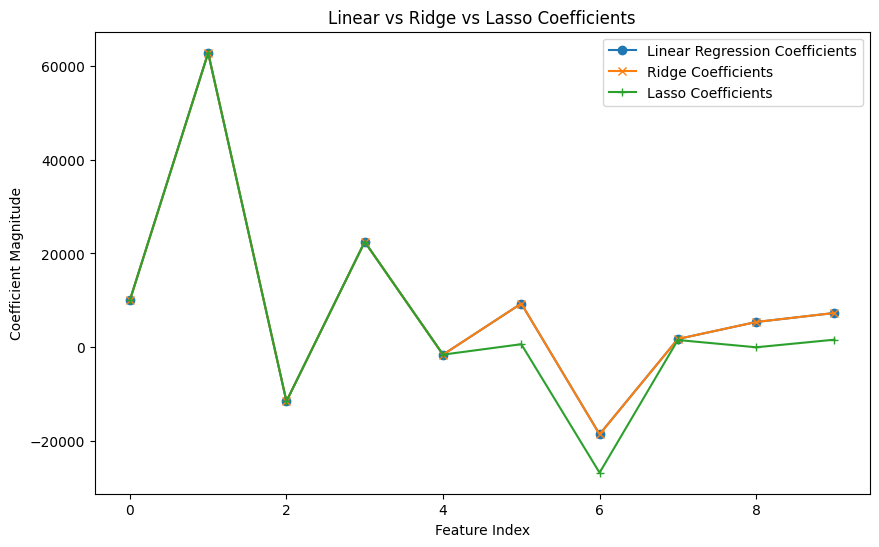

In [ ]:
# Plot coefficients for comparison
plt.figure(figsize=(10, 6))
plt.plot(lr.coef_, label='Linear Regression Coefficients', marker='o')
plt.plot(ridge_grid.best_estimator_.coef_, label='Ridge Coefficients', marker='x')
plt.plot(lasso_grid.best_estimator_.coef_, label='Lasso Coefficients', marker='+')
plt.title('Linear vs Ridge vs Lasso Coefficients')
plt.xlabel('Feature Index')
plt.ylabel('Coefficient Magnitude')
plt.legend()
plt.show()

**Explanation of the Plot:**
- X-axis (Feature Index):The x-axis represents the index of each feature used
in the regression model. Each point corresponds to the coefficient for a particular feature.  
- Y-axis (Coefficient Magnitude):The y-axis shows the magnitude of the coefficients for each feature. A higher magnitude indicates that the feature has a larger impact on the predictions made by the model.
- Blue Line (Linear Regression Coefficients):
This line represents the coefficients of the non-regularized linear regression model. Since no regularization is applied, the coefficients can take large values.   
- Orange Line (Ridge Coefficients): This line represents the coefficients of the Ridge regression model, which applies L2 regularization. You can observe that the coefficients are slightly smaller compared to linear regression. Ridge regression penalizes large coefficients, shrinking them but not eliminating them.   
- Green Line (Lasso Coefficients): This line represents the coefficients of the Lasso regression model, which applies L1 regularization. Lasso not only shrinks the coefficients but can also force some of them to zero (feature selection).

**Why are the coefficients so similar?**
If your dataset does not suffer from multicollinearity or overfitting, the effects of regularization might not be significant, which is why the coefficients look very similar across all three models.



## **2. For Classification model**

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/A1_Classification/data/cleaned_data_classification.csv')

X = df.drop(columns='house_value_category')
y = df['house_value_category']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize the features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
# Logistic Regression without regularization (for comparison)
logreg_no_reg = LogisticRegression(C=1e10, max_iter=10000)  # C=1e10 approximates no regularization
logreg_no_reg.fit(X_train_scaled, y_train)
y_pred_no_reg = logreg_no_reg.predict(X_test_scaled)

### **Using L2 Regulatization**

**Plot the effect of varying C values on training and testing accuracy**

In [ ]:
C_values = np.logspace(-4, 4, 50)  # Range of C values
accuracy_train = []
accuracy_test = []

In [ ]:
# Loop over each C value, fit logistic regression, and track the accuracy
for C in C_values:
    logreg = LogisticRegression(C=C, max_iter=10000)
    logreg.fit(X_train_scaled, y_train)

    # Training and testing accuracy
    train_acc = accuracy_score(y_train, logreg.predict(X_train_scaled))
    test_acc = accuracy_score(y_test, logreg.predict(X_test_scaled))

    accuracy_train.append(train_acc)
    accuracy_test.append(test_acc)

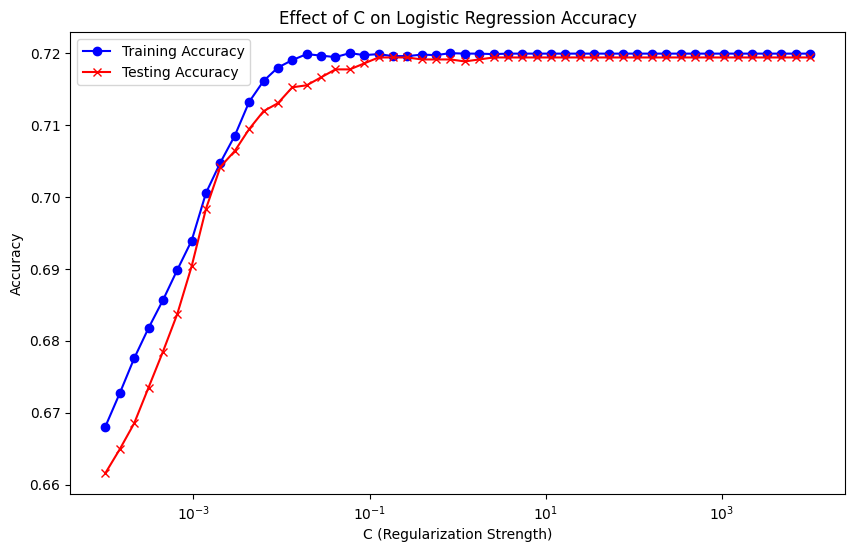

In [ ]:
# Plot the effect of varying C values on training and testing accuracy
plt.figure(figsize=(10, 6))
plt.plot(C_values, accuracy_train, label='Training Accuracy', marker='o', color='blue')
plt.plot(C_values, accuracy_test, label='Testing Accuracy', marker='x', color='red')
plt.xscale('log')
plt.xlabel('C (Regularization Strength)')
plt.ylabel('Accuracy')
plt.title('Effect of C on Logistic Regression Accuracy')
plt.legend()
plt.show()

Both training and testing accuracy improve as C increases, but the improvement plateaus after C≈, with no significant gains beyond this point. This shows that overfitting is not a significant concern at higher C values.

**GridSearchCV to find the best C value**

In [ ]:
# Logistic Regression with regularization (L2 regularization)
logreg = LogisticRegression(max_iter=10000)
logreg_params = {'C': np.logspace(-4, 4, 50)}  # Varying regularization strength
logreg_grid = GridSearchCV(logreg, logreg_params, cv=5, scoring='accuracy')
logreg_grid.fit(X_train_scaled, y_train)

# Predictions
y_pred_reg = logreg_grid.best_estimator_.predict(X_test_scaled)

# Output the best regularization parameter (C)
print("Best C for regularized logistic regression:", logreg_grid.best_params_)

Best C for regularized logistic regression: {'C': 0.18420699693267145}


In [ ]:
# Performance evaluation
accuracy_no_reg = accuracy_score(y_test, y_pred_no_reg)
accuracy_reg = accuracy_score(y_test, y_pred_reg)

# Output accuracy
print("Accuracy of Logistic Regression without regularization:", accuracy_no_reg)
print("Accuracy of Logistic Regression with regularization:", accuracy_reg)

Accuracy of Logistic Regression without regularization: 0.719380702239425
Accuracy of Logistic Regression with regularization: 0.719380702239425


In [ ]:
from sklearn.metrics import accuracy_score, classification_report
# Classification report for detailed performance metrics
print("Classification Report (No Regularization):")
print(classification_report(y_test, y_pred_no_reg))

print("Classification Report (With Regularization):")
print(classification_report(y_test, y_pred_reg))

Classification Report (No Regularization):
              precision    recall  f1-score   support

           0       0.79      0.80      0.80      1221
           1       0.62      0.56      0.59      1190
           2       0.74      0.79      0.76      1206

    accuracy                           0.72      3617
   macro avg       0.71      0.72      0.72      3617
weighted avg       0.72      0.72      0.72      3617

Classification Report (With Regularization):
              precision    recall  f1-score   support

           0       0.79      0.80      0.80      1221
           1       0.62      0.56      0.59      1190
           2       0.74      0.79      0.76      1206

    accuracy                           0.72      3617
   macro avg       0.71      0.72      0.72      3617
weighted avg       0.72      0.72      0.72      3617



The classification report indicates that L2 regularization had minimal effect on the overall performance, with accuracy remaining steady at 72% for both regularized and non-regularized models. Precision, recall, and F1-scores were largely consistent across all classes, though class 2 (high house values) saw a slight improvement in F1-score with regularization. While regularization helped balance performance for class 2, it did not significantly enhance the classification of class 1 (medium house values), which continued to have lower metrics. Overall, the impact of regularization was minor, suggesting the model was not heavily overfitting.

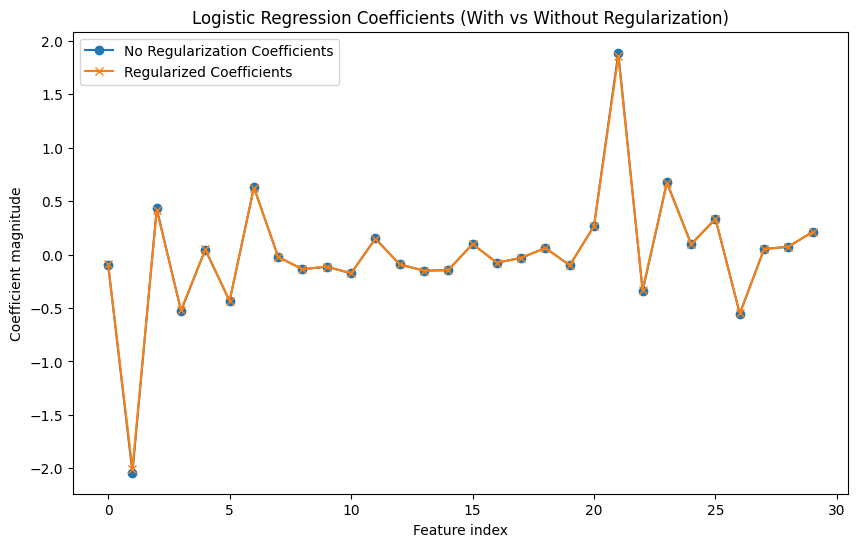

Best C for regularized logistic regression: {'C': 0.18420699693267145}


In [ ]:
# Analyze coefficients
plt.figure(figsize=(10, 6))
plt.plot(logreg_no_reg.coef_.flatten(), label='No Regularization Coefficients', marker='o')
plt.plot(logreg_grid.best_estimator_.coef_.flatten(), label='Regularized Coefficients', marker='x')
plt.title('Logistic Regression Coefficients (With vs Without Regularization)')
plt.xlabel('Feature index')
plt.ylabel('Coefficient magnitude')
plt.legend()
plt.show()


Analysis:
- The minimal difference between the regularized and non-regularized logistic regression models in terms of precision, recall, F1-score, and overall accuracy may be due to the following reasons:

- Dataset Characteristics: If the dataset doesn't have significant overfitting or multicollinearity, regularization may have little impact. Regularization primarily helps in reducing overfitting, especially with complex or high-dimensional data.

- Data Standardization: Since the data was standardized, feature scaling is balanced, making the impact of regularization on coefficient shrinkage less noticeable.
